# 03 – Prédiction des cartes d'occupation du sol (2017, 2021, 2025)

Application du modèle du notebook 02 aux images complètes des trois années.

- même normalisation que pour l'entraînement (percentiles de l'image 2021, dans `normalisation.json`)
- le modèle travaille sur des patches de 128 px : parcours de l'image par **fenêtre glissante avec recouvrement**, probabilités moyennées avec plus de poids au centre des patches (les bords d'un patch ont moins de contexte, donc sont moins bien prédits)
- 2021 sert de contrôle : comparaison avec WorldCover sur toute la zone

Les cartes (classe + confiance) sont sauvegardées en GeoTIFF dans `resultats/cartes/` pour le notebook 04.

## 1. Configuration et chargement du modèle

In [1]:
import json
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import rasterio
import tensorflow as tf
from tensorflow import keras

DATA_DIR = Path("data_saclay")
RES_DIR = Path("resultats")
CARTES_DIR = RES_DIR / "cartes"
CARTES_DIR.mkdir(parents=True, exist_ok=True)

ANNEES = ["2017", "2021", "2025"]
NOMS_CLASSES = ["Bâti", "Forêt / arbres", "Cultures", "Prairies / autre", "Eau"]
N_CLASSES = len(NOMS_CLASSES)
NODATA = 255
COULEURS = ListedColormap(["#d7191c", "#1a9641", "#fdae61", "#a6d96a", "#2b83ba"])

PATCH = 128
STRIDE = 64        # recouvrement de 50 % entre patches
BATCH = 64

model = keras.models.load_model(RES_DIR / "unet_saclay.keras")
with open(RES_DIR / "normalisation.json") as f:
    norm = json.load(f)
p_bas, p_haut = np.array(norm["p_bas"], "float32"), np.array(norm["p_haut"], "float32")
print("Modèle chargé :", model.name, f"({model.count_params():,} paramètres)")

2026-10-15 12:20:04.217745: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M4 Max
2026-10-15 12:20:04.217769: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 64.00 GB
2026-10-15 12:20:04.217772: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 25.92 GB
I0000 00:00:1792059604.217782 18606597 pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
I0000 00:00:1792059604.217798 18606597 pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)


Modèle chargé : unet_saclay (7,855,909 paramètres)


## 2. Prédiction par fenêtre glissante

Pondération des patches par une fenêtre de Hann 2D (≈ 1 au centre, proche de 0 sur les bords). L'image est complétée par réflexion pour que ses bords soient aussi couverts par le centre d'un patch.

J'ai aussi testé un **appariement d'histogrammes** (distribution de chaque bande de 2017 et 2025 ajustée sur celle de 2021). Il n'est finalement pas utilisé (`APPARIEMENT = False`), voir les observations.

In [2]:
APPARIEMENT = False   # appariement d'histogrammes sur 2021 (testé, non retenu)

with rasterio.open(DATA_DIR / "s2_2021.tif") as src:
    ref = np.moveaxis(src.read().astype("float32"), 0, -1)
ref_valide = ref[~(ref == 0).all(axis=-1)]
QUANTILES = np.linspace(0, 1, 1001)
REF_Q = np.quantile(ref_valide, QUANTILES, axis=0)   # quantiles de 2021, par bande
del ref, ref_valide


def apparier(img, vide):
    # ajuste la distribution de chaque bande sur celle de 2021
    out = img.copy()
    for b in range(img.shape[-1]):
        src_q = np.quantile(img[~vide, b], QUANTILES)
        out[~vide, b] = np.interp(img[~vide, b], src_q, REF_Q[:, b])
    return out


def charger(annee):
    with rasterio.open(DATA_DIR / f"s2_{annee}.tif") as src:
        img = np.moveaxis(src.read().astype("float32"), 0, -1)
        profil = src.profile
    vide = (img == 0).all(axis=-1)
    if APPARIEMENT and annee != "2021":
        img = apparier(img, vide)
    img = np.clip((img - p_bas) / (p_haut - p_bas), 0, 1)
    img[vide] = 0
    return img, vide, profil

hann = np.hanning(PATCH + 2)[1:-1]

POIDS_PATCH = np.outer(hann, hann).astype("float32")[..., None]


def predire_image(img):
    H, W, _ = img.shape
    m = PATCH // 2
    # padding pour couvrir les bords + arrondi à un multiple du pas
    ph = m + (-(H + 2 * m - PATCH) % STRIDE)
    pw = m + (-(W + 2 * m - PATCH) % STRIDE)
    img_p = np.pad(img, ((m, ph), (m, pw), (0, 0)), mode="reflect")
    Hp, Wp, _ = img_p.shape

    somme = np.zeros((Hp, Wp, N_CLASSES), "float32")
    poids = np.zeros((Hp, Wp, 1), "float32")
    positions = [(y, x) for y in range(0, Hp - PATCH + 1, STRIDE) for x in range(0, Wp - PATCH + 1, STRIDE)]
    print(f"  {len(positions)} patches à prédire")

    for i in range(0, len(positions), BATCH):
        lot = positions[i:i + BATCH]
        X = np.stack([img_p[y:y + PATCH, x:x + PATCH] for y, x in lot])
        P = model.predict(X, verbose=0)
        for (y, x), p in zip(lot, P):
            somme[y:y + PATCH, x:x + PATCH] += p * POIDS_PATCH
            poids[y:y + PATCH, x:x + PATCH] += POIDS_PATCH

    proba = somme[m:m + H, m:m + W] / np.maximum(poids[m:m + H, m:m + W], 1e-6)
    return proba

In [3]:
import time

cartes = {}
for annee in ANNEES:
    print(f"===== {annee} =====")
    t0 = time.time()
    img, vide, profil = charger(annee)
    proba = predire_image(img)
    carte = proba.argmax(-1).astype("uint8")
    carte[vide] = NODATA
    cartes[annee] = carte

    profil.update(count=1, dtype="uint8", nodata=NODATA, compress="deflate")
    with rasterio.open(CARTES_DIR / f"occupation_{annee}.tif", "w", **profil) as dst:
        dst.write(carte, 1)
    # confiance du modèle (proba max), utile pour repérer les zones douteuses
    profil_c = {**profil, "dtype": "float32", "nodata": None}
    with rasterio.open(CARTES_DIR / f"confiance_{annee}.tif", "w", **profil_c) as dst:
        dst.write(proba.max(-1), 1)
    print(f"  terminé en {time.time() - t0:.0f} s -> {CARTES_DIR / f'occupation_{annee}.tif'}")

===== 2017 =====
  3776 patches à prédire


2026-10-15 12:20:07.968415: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.


  terminé en 7 s -> resultats/cartes/occupation_2017.tif
===== 2021 =====
  3776 patches à prédire
  terminé en 7 s -> resultats/cartes/occupation_2021.tif
===== 2025 =====
  3776 patches à prédire
  terminé en 7 s -> resultats/cartes/occupation_2025.tif


## 3. Cartes obtenues

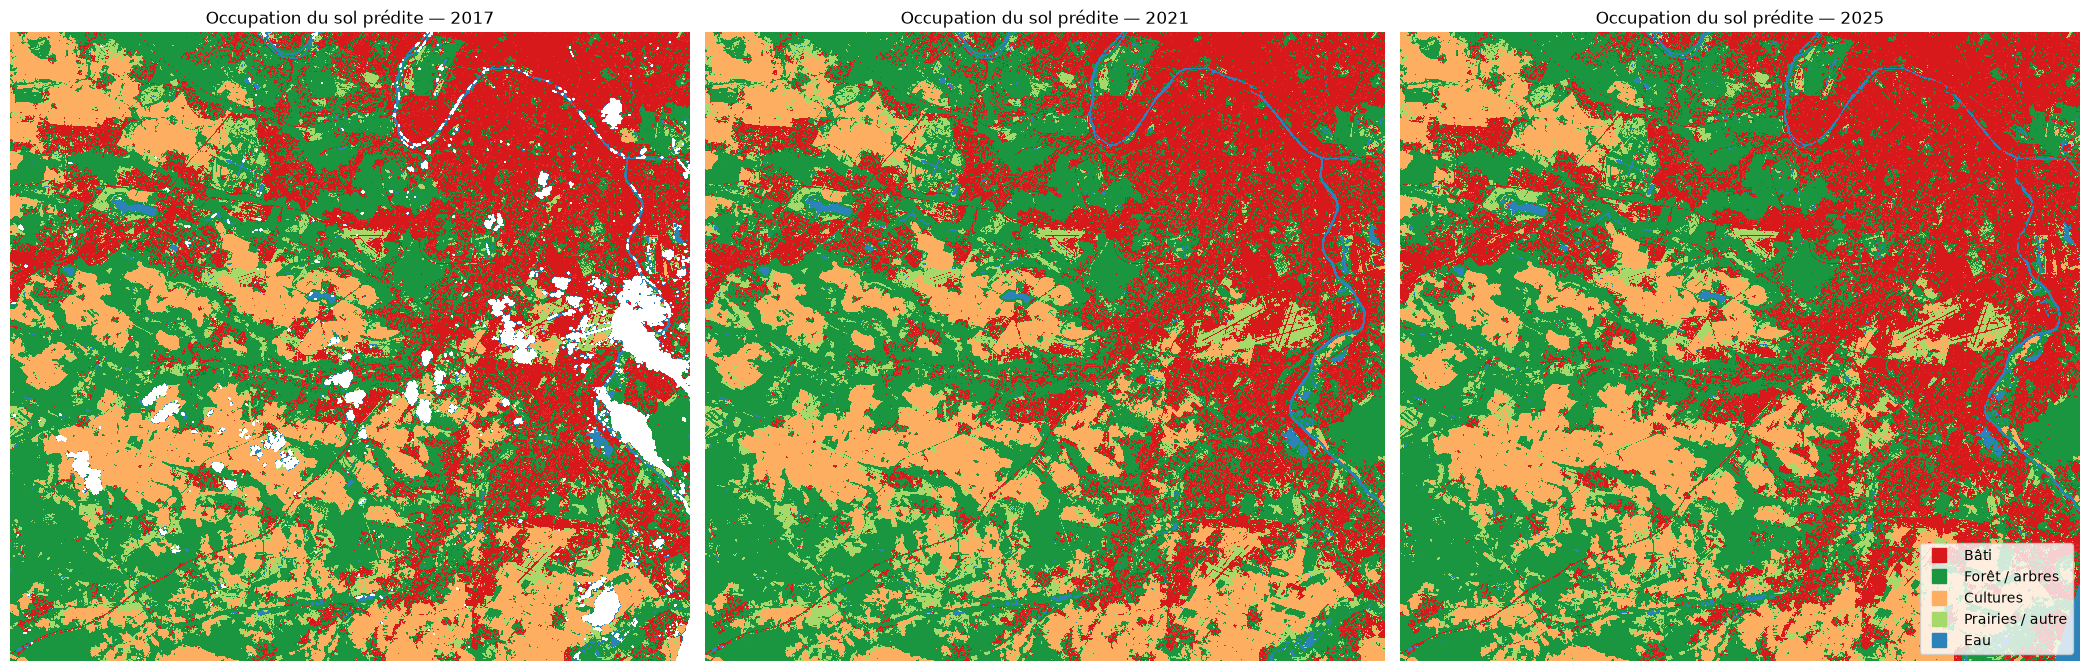

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(21, 7))
for ax, annee in zip(axes, ANNEES):
    ax.imshow(np.ma.masked_equal(cartes[annee], NODATA), cmap=COULEURS, vmin=0, vmax=4, interpolation="nearest")
    ax.set_title(f"Occupation du sol prédite — {annee}")
    ax.axis("off")
for i, nom in enumerate(NOMS_CLASSES):
    axes[-1].plot([], [], "s", color=COULEURS(i), label=nom, markersize=10)
axes[-1].legend(loc="lower right")
plt.tight_layout()
plt.savefig(RES_DIR / "cartes_occupation.png", dpi=120, bbox_inches="tight")
plt.show()

## 4. Répartition des classes par année

In [5]:
surf_pixel_km2 = 10 * 10 / 1e6
print(f"{'Classe':18s}" + "".join(f"{a:>14s}" for a in ANNEES))
repartition = {}
for c, nom in enumerate(NOMS_CLASSES):
    ligne = []
    for annee in ANNEES:
        carte = cartes[annee]
        valides = carte != NODATA
        part = (carte[valides] == c).mean()
        ligne.append(part)
        repartition.setdefault(annee, {})[nom] = {"part": float(part), "km2": float((carte == c).sum() * surf_pixel_km2)}
    print(f"{nom:18s}" + "".join(f"{p:14.1%}" for p in ligne))

with open(RES_DIR / "repartition_classes.json", "w", encoding="utf-8") as f:
    json.dump(repartition, f, indent=2, ensure_ascii=False)

Classe                      2017          2021          2025
Bâti                       30.4%         30.6%         33.1%
Forêt / arbres             40.5%         41.3%         38.7%
Cultures                   18.8%         17.2%         17.9%
Prairies / autre            8.7%          9.5%          8.8%
Eau                         1.6%          1.4%          1.6%


## 5. Contrôle sur 2021 : prédiction vs WorldCover

Comparaison avec WorldCover sur toute la zone. La majorité des pixels a servi à l'entraînement, donc ce score est optimiste ; le vrai score de généralisation est celui du jeu de test (notebook 02).

In [6]:
with rasterio.open(DATA_DIR / "labels_2021.tif") as src:
    wc = src.read(1)

valide = (wc != NODATA) & (cartes["2021"] != NODATA)
accord = (wc[valide] == cartes["2021"][valide]).mean()
print(f"Accord global prédiction 2021 / WorldCover : {accord:.1%}")
for c, nom in enumerate(NOMS_CLASSES):
    inter = ((wc == c) & (cartes["2021"] == c) & valide).sum()
    union = (((wc == c) | (cartes["2021"] == c)) & valide).sum()
    print(f"  IoU {nom:18s} {inter / max(union, 1):.3f}")

Accord global prédiction 2021 / WorldCover : 88.8%
  IoU Bâti               0.819
  IoU Forêt / arbres     0.835
  IoU Cultures           0.860
  IoU Prairies / autre   0.535
  IoU Eau                0.726


## 6. Zoom sur le plateau de Saclay

Secteur du campus Paris-Saclay (fenêtre de 4 km), où les chantiers ont été importants entre 2017 et 2025.

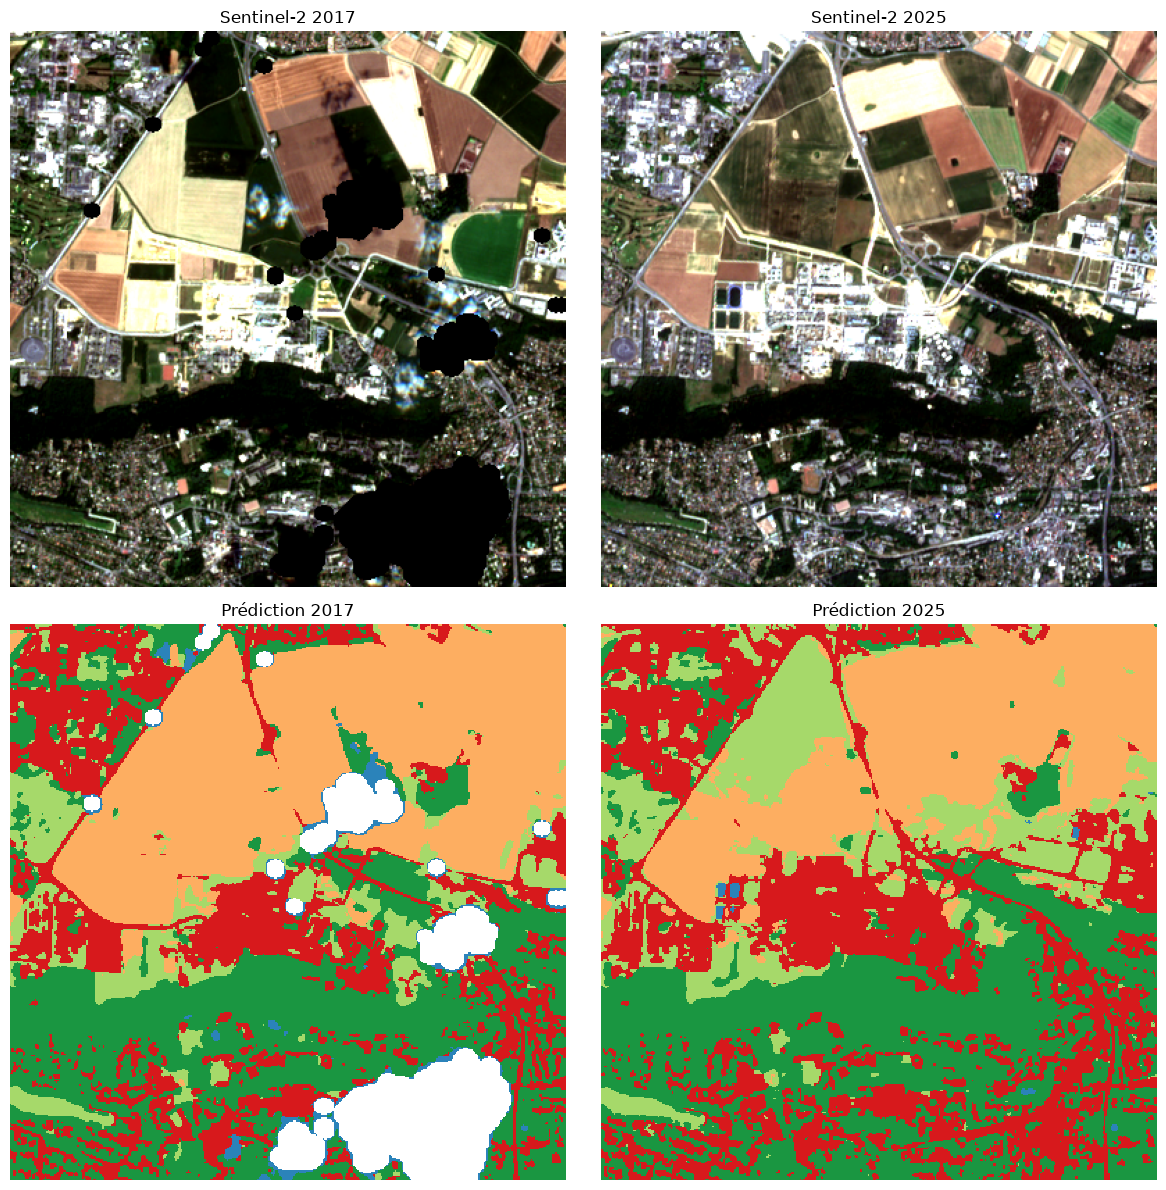

In [7]:
# Fenêtre de 4 km centrée sur le campus Paris-Saclay
from rasterio.warp import transform

with rasterio.open(DATA_DIR / "s2_2021.tif") as src:
    xs, ys = transform("EPSG:4326", src.crs, [2.17], [48.712])
    ligne, col = src.index(xs[0], ys[0])
T = 400  # 4 km
zone = (slice(max(ligne - T // 2, 0), ligne + T // 2), slice(max(col - T // 2, 0), col + T // 2))

def rgb(annee):
    img, _, _ = charger(annee)
    return np.clip(img[zone][..., [2, 1, 0]] * 1.2, 0, 1)

fig, axes = plt.subplots(2, 2, figsize=(12, 12))
for j, annee in enumerate(["2017", "2025"]):
    axes[0, j].imshow(rgb(annee))
    axes[0, j].set_title(f"Sentinel-2 {annee}")
    axes[1, j].imshow(np.ma.masked_equal(cartes[annee][zone], NODATA), cmap=COULEURS, vmin=0, vmax=4, interpolation="nearest")
    axes[1, j].set_title(f"Prédiction {annee}")
for ax in axes.ravel():
    ax.axis("off")
plt.tight_layout()
plt.savefig(RES_DIR / "zoom_saclay.png", dpi=120, bbox_inches="tight")
plt.show()

## Observations

**Transfert du modèle d'une date à l'autre.** Ça a été la principale difficulté du projet. Part du bâti, des cultures et de l'eau selon les essais successifs :

| Essai | Bâti 2017 | Bâti 2021 | Bâti 2025 | Cultures 2017 | Eau 2017 |
|---|---|---|---|---|---|
| 1. modèle initial, image du 18/06/2017 | 24,6 % | 30,6 % | 34,9 % | 21,8 % | 4,9 % |
| 2. + appariement d'histogrammes | 35,3 % | 30,6 % | 30,7 % | 17,3 % | 1,4 % |
| 3. modèle avec augmentation radiométrique + appariement | 34,4 % | 30,6 % | 31,3 % | 10,0 % | 1,3 % |
| 4. modèle avec augmentation radiométrique, sans appariement | 30,4 % | 30,6 % | 33,1 % | 11,9 % | 1,5 % |
| **5. idem, image du 18/07/2017 (version finale)** | **30,4 %** | **30,6 %** | **33,1 %** | **18,8 %** | **1,6 %** |

- Essai 1 : en 2017 l'eau triple (4,9 % contre 1,5 %) alors que la surface en eau ne change pas → le modèle prend les ombres de l'image 2017, plus sombre, pour de l'eau. Le bâti passe de 24,6 % à 34,9 %, soit ~150 km² en 8 ans : impossible.
- Essai 2 : l'appariement règle l'eau mais inverse le problème (plus de bâti en 2017 qu'en 2025). Il suppose que les paysages ont la même composition aux deux dates, ce qui n'est pas le cas (champs verts / champs jaunes), donc il déforme les autres classes.
- Essais 3–4 : l'augmentation radiométrique à l'entraînement suffit pour l'eau, sans toucher aux images. Mais les cultures de 2017 restent très basses (10–12 %) : l'image de juin a des blés encore verts, classés en prairies. C'est un problème de saison, pas de couleurs.
- Essai 5 : avec l'image du 18 juillet les cultures 2017 reviennent au niveau des autres années (18,8 %).

**Contrôle 2021** : 88,8 % d'accord avec WorldCover sur toute la zone (IoU bâti 0,82), cohérent avec le jeu de test.

**Limites des totaux.** Même dans la version finale, les surfaces totales ne sont pas fiables pour mesurer l'artificialisation : le bâti ne bouge pas entre 2017 et 2021 alors que c'est la période des gros chantiers, et +2,5 points entre 2021 et 2025 (~36 km²) est beaucoup trop. Une partie vient de quartiers pavillonnaires inchangés classés un peu plus souvent en bâti en 2025. D'où le calcul par flux de pixels dans le notebook 04.

**Zoom sur le campus** : le nouveau quartier sur les anciennes parcelles agricoles, l'emprise de la ligne 18 et les bassins de rétention apparaissent nettement en 2025. Restent quelques défauts : un liseré classé en eau autour des nuages masqués de 2017, et des variations bâti / forêt dans le pavillonnaire.